# Практична робота №20
## Лінійне програмування: постановка задачі та розв'язання засобами SciPy

**Виконав:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Тема:** оптимізація тижневого випуску двох видів продукції

**Мета:** сформулювати математичну модель виробничої задачі, знайти оптимальний прибуток за допомогою `scipy.optimize.linprog`, визначити активні обмеження та дослідити вплив збільшення доступних ресурсів.

**Вхідні дані варіанта №5:**

| Показник | Виріб А | Виріб Б | Тижневий ліміт |
|:--|--:|--:|--:|
| Прибуток, грн/од. | 44 | 48 | — |
| Сировина, кг/од. | 4 | 3 | 195 кг |
| Машинний час, год/од. | 2 | 4 | 160 год |
| Електроенергія, кВт·год/од. | 1 | 1 | 70 кВт·год |

## Завдання 1. Математична постановка задачі

**Змінні рішення:**

- $x_1$ — кількість одиниць **виробу А**, які потрібно виготовити за тиждень;
- $x_2$ — кількість одиниць **виробу Б**, які потрібно виготовити за тиждень.

**Цільова функція (максимізація тижневого прибутку, грн):**

$$\boxed{\max P=44x_1+48x_2}$$

**Ресурсні обмеження:**

$$\begin{aligned}
4x_1+3x_2 &\le 195 &&\text{(сировина, кг)}\\
2x_1+4x_2 &\le 160 &&\text{(машинний час, год)}\\
x_1+x_2 &\le 70 &&\text{(електроенергія, кВт·год)}\\
x_1 &\ge 0, \qquad x_2\ge 0 &&\text{(невід'ємність).}
\end{aligned}$$

За умовою `linprog` **мінімізує** функцію, тому для максимізації $P$ мінімізуватимемо $-P=-44x_1-48x_2$. Усі три ресурсні нерівності вже мають потрібний вигляд $A_{ub}x\le b_{ub}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from IPython.display import display

plt.rcParams['font.family'] = 'DejaVu Sans'
pd.options.display.float_format = '{:.3f}'.format

city = 'Дніпро'
variant = 5
profits = np.array([44.0, 48.0])  # грн/од.
A_ub = np.array([
    [4.0, 3.0],  # сировина (кг)
    [2.0, 4.0],  # машинний час (год)
    [1.0, 1.0],  # електроенергія (кВт·год)
])
b_ub = np.array([195.0, 160.0, 70.0])
resource_names = ['Сировина', 'Машинний час', 'Електроенергія']
resource_units = ['кг', 'год', 'кВт·год']

print(f'Місто: {city} | варіант: {variant}')
print('Вектор прибутку:', profits)
print('Матриця використання ресурсів:\n', A_ub)
print('Вектор ресурсних лімітів:', b_ub)

Місто: Дніпро | варіант: 5
Вектор прибутку: [44. 48.]
Матриця використання ресурсів:
 [[4. 3.]
 [2. 4.]
 [1. 1.]]
Вектор ресурсних лімітів: [195. 160.  70.]


## Завдання 2. Розв'язання через `linprog`

Для методу `highs` встановлюємо цільовий вектор $c=(-44,-48)$, обмеження з Завдання 1 та невід'ємні межі змінних. Показник `res.fun` є **від'ємним максимальним прибутком**, тому остаточний прибуток обчислюємо як `-res.fun`.

In [2]:
res = linprog(
    c=-profits,
    A_ub=A_ub,
    b_ub=b_ub,
    bounds=[(0, None), (0, None)],
    method='highs',
)

print('res.x:', res.x)
print('res.fun:', res.fun)
print('res.status:', res.status)
print('res.message:', res.message)

assert res.status == 0 and res.success, 'Оптимальний розв’язок не знайдено!'
assert np.all(A_ub @ res.x <= b_ub + 1e-7), 'Порушено ресурсні обмеження!'
assert np.all(res.x >= -1e-7), 'Порушено невід’ємність!'
max_profit = -res.fun
print(f'Максимальний тижневий прибуток = {max_profit:.2f} грн')

res.x: [30. 25.]
res.fun: -2520.0
res.status: 0
res.message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Максимальний тижневий прибуток = 2520.00 грн


## Завдання 3. Змістовна інтерпретація оптимального плану

Отримано **$x_1=30$ одиниць виробу А** та **$x_2=25$ одиниць виробу Б** на тиждень. Загальний прибуток:

$$P_{\max}=44\cdot30+48\cdot25=1320+1200=\boxed{2520\ \text{грн/тиждень}}.$$

У базовому варіанті оптимальний розв'язок **уже цілочисловий**, тому він придатний для планування випуску цілих виробів без коригування. Водночас звичайний `linprog` розв'язує **неперервну** задачу й в інших сценаріях може повернути дробові значення: це не означає, що дозволено буквально випускати частину неподільного виробу. Просте округлення не гарантує допустимості обмежень і тим більше не гарантує оптимального цілочислового прибутку; для реального виробництва тоді застосовують цілочислове програмування (`scipy.optimize.milp`) або інший точний метод.

,Виріб,"Кількість, шт./тиждень","Прибуток за од., грн","Прибуток разом, грн"
0,А,30.000,44.000,1320.000
1,Б,25.000,48.000,1200.000


Перевірка прибутку: 2520.0 грн


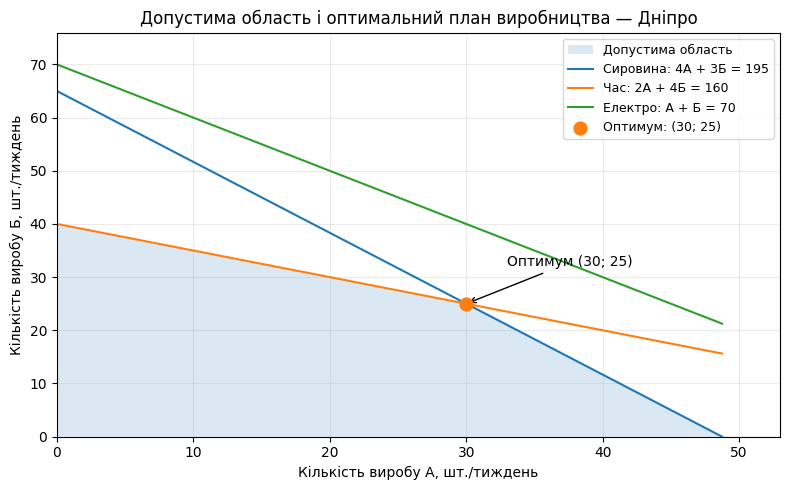

In [3]:
solution_table = pd.DataFrame({
    'Виріб': ['А', 'Б'],
    'Кількість, шт./тиждень': res.x,
    'Прибуток за од., грн': profits,
    'Прибуток разом, грн': profits * res.x,
})
display(solution_table)
print('Перевірка прибутку:', float((profits * res.x).sum()), 'грн')
assert np.isclose((profits * res.x).sum(), max_profit)

# Додаткове наочне відображення допустимої області й оптимуму.
x_grid = np.linspace(0, b_ub[0] / A_ub[0, 0], 400)
raw_y = (b_ub[0] - A_ub[0, 0] * x_grid) / A_ub[0, 1]
time_y = (b_ub[1] - A_ub[1, 0] * x_grid) / A_ub[1, 1]
energy_y = (b_ub[2] - A_ub[2, 0] * x_grid) / A_ub[2, 1]
y_feasible = np.maximum(0, np.minimum.reduce([raw_y, time_y, energy_y]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(x_grid, y_feasible, 0, alpha=0.17, label='Допустима область')
ax.plot(x_grid, raw_y, label='Сировина: 4A + 3Б = 195')
ax.plot(x_grid, time_y, label='Час: 2A + 4Б = 160')
ax.plot(x_grid, energy_y, label='Електро: A + Б = 70')
ax.scatter(res.x[0], res.x[1], s=85, zorder=5, label='Оптимум: (30; 25)')
ax.annotate('Оптимум (30; 25)', xy=res.x, xytext=(33, 32),
            arrowprops={'arrowstyle': '->'})
ax.set(xlim=(0, 53), ylim=(0, 76),
       xlabel='Кількість виробу А, шт./тиждень',
       ylabel='Кількість виробу Б, шт./тиждень',
       title='Допустима область і оптимальний план виробництва — Дніпро')
ax.grid(alpha=0.25)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

## Завдання 4. Активні та неактивні ресурсні обмеження

Обчислимо фактичне використання кожного ресурсу через $A_{ub}\cdot x$, а запас — через `res.slack`. Обмеження вважатимемо **активним**, якщо його залишок з урахуванням похибки обчислень дорівнює нулю (`np.isclose`).

In [4]:
used = A_ub @ res.x
slacks = res.slack
is_binding = np.isclose(slacks, 0, atol=1e-8)
resource_table = pd.DataFrame({
    'Ресурс': resource_names,
    'Одиниця': resource_units,
    'Використано': used,
    'Ліміт': b_ub,
    'Запас (slack)': slacks,
    'Стан': np.where(is_binding, 'Активне', 'Неактивне'),
})
display(resource_table)
print('res.slack:', slacks)

# Для задачі максимізації -marginals є локальною оцінкою додаткового прибутку
# від збільшення доступного ресурсу на одиницю, доки оптимальний базис не зміниться.
shadow_values = -res.ineqlin.marginals
shadow_table = pd.DataFrame({
    'Ресурс': resource_names,
    'Приріст прибутку за +1 од. ресурсу (локально), грн': shadow_values,
})
display(shadow_table)

assert np.allclose(slacks, b_ub - used)
assert is_binding.tolist() == [True, True, False]

,Ресурс,Одиниця,Використано,Ліміт,Запас (slack),Стан
0,Сировина,кг,195.000,195.000,0.000,Активне
1,Машинний час,год,160.000,160.000,0.000,Активне
2,Електроенергія,кВт·год,55.000,70.000,15.000,Неактивне


res.slack: [ 0.  0. 15.]


,Ресурс,"Приріст прибутку за +1 од. ресурсу (локально), грн"
0,Сировина,8.000
1,Машинний час,6.000
2,Електроенергія,0.000


**Інтерпретація.** Усі **195 кг сировини** та **160 машино-годин** витрачаються повністю: це **активні** обмеження, які стримують подальше збільшення прибутку. Електроенергії використано **55 із 70 кВт·год**, тобто **15 кВт·год залишається**: це неактивне обмеження, і збільшення запасу електроенергії саме по собі не покращить оптимум.

За поточного оптимального плану граничні («тіньові») оцінки ресурсів становлять приблизно **8 грн за додатковий кг сировини** та **6 грн за додаткову машино-годину**; для електроенергії — **0 грн за кВт·год**. Ці числа є **локальними**: при великій зміні лімітів структура активних обмежень може змінитися. Доцільно розглядати розширення сировини й/або машинного часу, враховуючи також фактичну **вартість** розширення ресурсу; просто «активність» не означає автоматичної економічної вигідності будь-якої інвестиції.

## Завдання 5. What-if: зміна доступних ресурсів

Досліджуємо два незалежні сценарії **від базових умов**, а не послідовне накопичення змін:

1. **Активний ресурс — сировина:** збільшуємо ліміт на 15%, з 195 до $195\cdot1{,}15=224{,}25$ кг; інші ліміти без змін.
2. **Неактивний ресурс — електроенергія:** збільшуємо ліміт на 50%, з 70 до $70\cdot1{,}5=105$ кВт·год; інші ліміти без змін.

In [5]:
b_more_raw = b_ub.copy()
b_more_raw[0] *= 1.15
res_raw = linprog(-profits, A_ub=A_ub, b_ub=b_more_raw,
                  bounds=[(0, None)] * 2, method='highs')

b_more_energy = b_ub.copy()
b_more_energy[2] *= 1.50
res_energy = linprog(-profits, A_ub=A_ub, b_ub=b_more_energy,
                     bounds=[(0, None)] * 2, method='highs')

assert res_raw.success and res_energy.success
assert np.all(A_ub @ res_raw.x <= b_more_raw + 1e-7)
assert np.all(A_ub @ res_energy.x <= b_more_energy + 1e-7)

scenario_table = pd.DataFrame([
    {
        'Сценарій': 'Початковий', 'Виріб А, шт.': res.x[0],
        'Виріб Б, шт.': res.x[1], 'Прибуток, грн': -res.fun,
        'Зміна прибутку, грн': 0.0,
    },
    {
        'Сценарій': 'Сировина +15%', 'Виріб А, шт.': res_raw.x[0],
        'Виріб Б, шт.': res_raw.x[1], 'Прибуток, грн': -res_raw.fun,
        'Зміна прибутку, грн': -res_raw.fun + res.fun,
    },
    {
        'Сценарій': 'Електроенергія +50%', 'Виріб А, шт.': res_energy.x[0],
        'Виріб Б, шт.': res_energy.x[1], 'Прибуток, грн': -res_energy.fun,
        'Зміна прибутку, грн': -res_energy.fun + res.fun,
    },
])
display(scenario_table)

print('Нові запаси при збільшенні сировини:', np.round(res_raw.slack, 4))
print('Нові запаси при збільшенні електроенергії:', np.round(res_energy.slack, 4))
print(f'Відносний приріст прибутку при +15% сировини: '
      f'{(-res_raw.fun / max_profit - 1) * 100:.2f}%')

assert np.allclose(res_raw.x, [41.7, 19.15])
assert np.isclose(-res_raw.fun, 2754)
assert np.allclose(res_energy.x, res.x)
assert np.isclose(-res_energy.fun, max_profit)

,Сценарій,"Виріб А, шт.","Виріб Б, шт.","Прибуток, грн","Зміна прибутку, грн"
0,Початковий,30.000,25.000,2520.000,0.000
1,Сировина +15%,41.700,19.150,2754.000,234.000
2,Електроенергія +50%,30.000,25.000,2520.000,0.000


Нові запаси при збільшенні сировини: [0.   0.   9.15]
Нові запаси при збільшенні електроенергії: [ 0.  0. 50.]
Відносний приріст прибутку при +15% сировини: 9.29%


### Пояснення сценаріїв

**1. Активний ресурс, сировина +15%.** Оптимальний *неперервний* план змінюється з $(30;25)$ до **$(41{,}70;19{,}15)$**, а прибуток — із **2520** до **2754 грн/тиждень**. Приріст — **234 грн (9,29%)**. Підприємство виготовляє більше виробу А та менше виробу Б, бо додаткова сировина дозволяє вигідно перебудувати випуск за збереженого обмеження машинного часу. У новому плані сировина й машинний час знову використані повністю, а електроенергії залишається **9,15 кВт·год**.

**2. Неактивний ресурс, електроенергія +50%.** Ліміт зростає до **105 кВт·год**, однак оптимальний план залишається **30 одиниць А і 25 одиниць Б**, а прибуток — **2520 грн**. Запас електроенергії збільшується до **50 кВт·год**: ресурс не був дефіцитним, тож додаткова його кількість не усуває обмеження сировини та часу.

**Важливе зауваження про цілі одиниці продукції.** У першому сценарії LP-розв'язок дробовий. Навіть округлення до найближчих цілих $x_1=42$, $x_2=19$ порушує новий ліміт сировини: $4\cdot42+3\cdot19=225>224{,}25$ кг. Тому для неподільної продукції треба розв'язувати **цілочислову** задачу. Нижче наведено невелику додаткову перевірку повним перебором для цього навчального випадку.

In [6]:
# Додаткова перевірка: цілочисловий випуск при +15% сировини.
# Через невеликі допустимі межі простий повний перебір є точним.
best_integer = None
for x_a in range(int(b_more_raw[0] // 4) + 1):
    for x_b in range(int(b_more_raw[1] // 4) + 1):
        proposal = np.array([x_a, x_b], dtype=float)
        if np.all(A_ub @ proposal <= b_more_raw + 1e-9):
            profit = profits @ proposal
            if best_integer is None or profit > best_integer[0]:
                best_integer = (profit, x_a, x_b)

print('Цілочисловий оптимум (сировина +15%):',
      f'А={best_integer[1]} шт., Б={best_integer[2]} шт., '
      f'прибуток={best_integer[0]:.0f} грн')
print('Неперервний оптимум:', f'{-res_raw.fun:.0f} грн')
print('Округлення [41.7, 19.15] до найближчих цілих:', np.rint(res_raw.x).astype(int))
print('Витрата сировини після такого округлення:', float(A_ub[0] @ np.rint(res_raw.x)), 'кг')
assert best_integer == (2720.0, 40, 20)

Цілочисловий оптимум (сировина +15%): А=40 шт., Б=20 шт., прибуток=2720 грн
Неперервний оптимум: 2754 грн
Округлення [41.7, 19.15] до найближчих цілих: [42 19]
Витрата сировини після такого округлення: 225.0 кг


## Відповіді на контрольні питання

**1. Чому `linprog` мінімізує і як знайти максимум?**  
За визначенням інтерфейсу `scipy.optimize.linprog` шукає **мінімум** переданої цільової функції. Тому для максимізації прибутку $P=44x_1+48x_2$ у програмі задаємо коефіцієнти $c=(-44,-48)$ і мінімізуємо $-P$. Справжній максимальний прибуток дорівнює `-res.fun`, а кількості виробів зберігаються у `res.x`.

**2. Чому нерівності «не менше» потрібно змінити?**  
Параметри `A_ub` та `b_ub` задають нерівності лише у формі $A_{ub}x\le b_{ub}$. Щоб описати умову, наприклад, $2x_1+3x_2\ge 50$, множимо **обидві** її частини на $-1$ і змінюємо напрям знака: $-2x_1-3x_2\le-50$. У нашій задачі всі ресурсні обмеження вже мають знак «$\le$», тому перетворення їм не потрібне.

**3. Чим активне обмеження відрізняється від неактивного?**  
Активне обмеження має нульовий запас (`slack ≈ 0`) — ресурс використано до ліміту. У Дніпрі це **195 кг сировини** та **160 год машинного часу**. Неактивне обмеження має додатний запас: електроенергії залишилось **15 кВт·год**. Активні ресурси є кандидатами на розширення виробництва, але економічна доцільність залежить від додаткових витрат і граничної вигоди.

**4. Чи узгоджуються результати «what-if» з активністю обмежень?**  
Так. Збільшення активного ліміту сировини на 15% підвищило максимальний неперервний прибуток із **2520 до 2754 грн**, оскільки усунуло частину ресурсного дефіциту. Збільшення неактивного ліміту електроенергії на 50% **не змінило** ані плану, ані прибутку, бо електроенергії спочатку було достатньо. Це демонструє роль активних ресурсних обмежень як поточних «вузьких місць».

## Висновок

Для виробничої дільниці міста **Дніпро** побудовано математичну задачу лінійного програмування з двома змінними, цільовою функцією максимізації прибутку та трьома ресурсними обмеженнями. Метод `linprog(method="highs")` знайшов оптимум — **30 виробів А, 25 виробів Б, 2520 грн прибутку за тиждень**. **Сировина й машинний час** виявилися активними ресурсами, **електроенергія** — неактивним ресурсом. Аналіз «what-if» показав, що підвищення ліміту сировини дає приріст прибутку, тоді як збільшення електроліміту не дає економічного ефекту. Для сценаріїв із дробовим оптимумом окремо пояснено необхідність цілочислової оптимізації.